# Exercise 4: Effect of Model Width and Depth on CIFAR-10

**Aim.** Investigate how changes in Convolutional Neural Network (CNN) **width** (number of convolutional kernels per hidden layer) and **depth** (number of trainable convolutional layers) affect classification performance, training behaviour, generalisation, and computational complexity on CIFAR-10.

**Experimental Design.** Using the Exercise 2 three-layer CNN (`3 -> 32 -> 64 -> 10` with global average pooling, 25,162 parameters) as the central reference architecture, we evaluate **six variations** across two controlled single-factor experiments:
- **Experiment A — Three Network Widths (at fixed depth = 3 trainable conv layers):**
  1. `Width 1 (Narrow: 16 -> 32 -> 10)` — $0.5\times$ baseline kernel counts (7,978 parameters)
  2. `Width 2 (Baseline: 32 -> 64 -> 10)` — $1.0\times$ baseline kernel counts (25,162 parameters)
  3. `Width 3 (Wide: 64 -> 128 -> 10)` — $2.0\times$ baseline kernel counts (87,178 parameters)
- **Experiment B — Three Network Depths (at fixed width progression `32 -> 64`):**
  4. `Depth 1 (Shallow, 2 conv: 32 -> 10)` — 1 hidden conv layer + output conv layer (3,786 parameters)
  5. `Depth 2 (Baseline, 3 conv: 32 -> 64 -> 10)` — 2 hidden conv layers + output conv layer (25,162 parameters)
  6. `Depth 3 (Deep, 5 conv: 32 -> 32 -> 64 -> 64 -> 10)` — 4 hidden conv layers (two conv layers per spatial stage) + output conv layer (71,338 parameters)

All six variations use the exact same seeded 45,000/5,000 train/validation split, per-channel normalisation constants, optimiser (`SGD lr=0.01, momentum=0.9`, selected on validation in Exercise 2), batch size (`128`), loss function (`CrossEntropyLoss`), and 30 training epochs. Computational complexity is measured by trainable parameters, multiply–accumulate operations (MACs) per image, and measured epoch time.

**How to run.** Install `requirements.txt`, start Jupyter, and use **Kernel > Restart Kernel and Run All**.

## 1. Setup: imports, reproducibility, and shared configuration

We load `outputs/exercise1 config.json` and `outputs/exercise2 config.json` so that the random seed (`42`), batch size (`128`), epoch count (`30`), per-channel RGB normalisation constants, 5,000 validation indices, and validation-selected CNN optimiser (`SGD lr=0.01, momentum=0.9`) remain identical to Exercises 2 and 3.

In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (DATA_DIR, OUTPUT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = OUTPUT_DIR / "exercise1 config.json"
EX2_CONFIG_PATH = OUTPUT_DIR / "exercise2 config.json"
for required_path, notebook in ((CONFIG_PATH, "Exercise 1 MLP.ipynb"), (EX2_CONFIG_PATH, "Exercise 2 CNN.ipynb")):
    if not required_path.exists():
        raise FileNotFoundError(f"'{required_path}' not found. Run '{notebook}' first.")

with CONFIG_PATH.open("r") as config_file:
    exercise1_config = json.load(config_file)

SEED = exercise1_config["seed"]
BATCH_SIZE = exercise1_config["batch_size"]
EPOCHS = exercise1_config["epochs"]
CHANNEL_MEAN = exercise1_config["normalisation"]["mean"]
CHANNEL_STD = exercise1_config["normalisation"]["std"]
VAL_INDICES = exercise1_config["validation_indices"]

with EX2_CONFIG_PATH.open("r") as config_file:
    exercise2_config = json.load(config_file)
OPTIMISER_NAME = exercise2_config["optimiser"]["name"]
OPTIMISER_CLASS = getattr(torch.optim, exercise2_config["optimiser"]["class"])
OPTIMISER_SETTINGS = exercise2_config["optimiser"]["settings"]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Seed: {SEED} | Batch size: {BATCH_SIZE} | Epochs: {EPOCHS} | Optimiser: {OPTIMISER_NAME}")

PyTorch 2.14.0+cu126 | device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Seed: 42 | Batch size: 128 | Epochs: 30 | Optimiser: SGD lr=0.01 momentum=0.9


**Setup Analysis.** By loading the exact configuration artefacts from Exercises 1 and 2, we guarantee that only the architectural dimensions (width and depth) vary across experiments while data partitioning, preprocessing, and optimisation settings remain strictly controlled (Requirement 4).

## 2. Dataset split and in-memory tensor preprocessing

As in Exercises 2 and 3, the 50,000 CIFAR-10 training images are split into 45,000 training images and 5,000 validation images using the saved `VAL_INDICES`, while the 10,000 test images remain completely separate for final evaluation. All partitions are normalised once into float32 `TensorDataset` tensors and iterated with a seeded `torch.Generator` so every architectural variation receives the exact same mini-batch sequence.

In [2]:
raw_train_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True)
CLASS_NAMES = raw_train_dataset.classes

val_index_set = set(VAL_INDICES)
TRAIN_INDICES = [idx for idx in range(len(raw_train_dataset)) if idx not in val_index_set]

mean_tensor = torch.tensor(CHANNEL_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
std_tensor = torch.tensor(CHANNEL_STD, dtype=torch.float32).view(1, 3, 1, 1)


def prepare_normalised_tensors(images_np, targets_list, indices=None):
    if indices is not None:
        images_np = images_np[indices]
        targets_list = [targets_list[i] for i in indices]
    x = torch.from_numpy(images_np).permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - mean_tensor) / std_tensor
    y = torch.tensor(targets_list, dtype=torch.long)
    return x, y


X_train, y_train = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, TRAIN_INDICES)
X_val, y_val = prepare_normalised_tensors(raw_train_dataset.data, raw_train_dataset.targets, VAL_INDICES)
X_test, y_test = prepare_normalised_tensors(raw_test_dataset.data, raw_test_dataset.targets)

train_tensor_dataset = TensorDataset(X_train, y_train)
val_tensor_dataset = TensorDataset(X_val, y_val)
test_tensor_dataset = TensorDataset(X_test, y_test)


def make_train_loader(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)


train_eval_loader = DataLoader(train_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_tensor_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training partition:   {len(train_tensor_dataset):,} images | tensor shape: {tuple(X_train.shape)}")
print(f"Validation partition: {len(val_tensor_dataset):,} images | tensor shape: {tuple(X_val.shape)}")
print(f"Test partition:       {len(test_tensor_dataset):,} images | tensor shape: {tuple(X_test.shape)}")
print(f"Overlap between train and val indices: {len(set(TRAIN_INDICES) & val_index_set)}")

Training partition:   45,000 images | tensor shape: (45000, 3, 32, 32)
Validation partition: 5,000 images | tensor shape: (5000, 3, 32, 32)
Test partition:       10,000 images | tensor shape: (10000, 3, 32, 32)
Overlap between train and val indices: 0


**Dataset Verification.** The training ($45,000$), validation ($5,000$), and test ($10,000$) partitions are verified with zero index overlap between training and validation.

## 3. Configurable CNN Architecture for Width and Depth Experiments

To satisfy Requirements 1, 2, and 3:
- **Width Investigation (3 Network Widths at Fixed Depth = 3 Trainable Layers):**
  We scale the number of convolutional kernels (`hidden_channels`) in each hidden layer in increasing order while keeping the depth fixed at 3 trainable convolutional layers (`Conv2d -> ReLU -> MaxPool2d -> Conv2d -> ReLU -> MaxPool2d -> Conv2d -> AdaptiveAvgPool2d(1)`):
  - **Width 1 (Narrow):** `[16, 32]` hidden kernels $\rightarrow$ 10 output channels (**7,978 parameters**)
  - **Width 2 (Baseline):** `[32, 64]` hidden kernels $\rightarrow$ 10 output channels (**25,162 parameters**)
  - **Width 3 (Wide):** `[64, 128]` hidden kernels $\rightarrow$ 10 output channels (**87,178 parameters**)

- **Depth Investigation (3 Network Depths at Fixed Channel Scale `32 -> 64`):**
  We vary the number of trainable convolutional layers while maintaining the baseline channel widths (`32` in stage 1, `64` in stage 2):
  - **Depth 1 (Shallow — 2 Trainable Layers):** `[32]` hidden kernels with one `MaxPool2d(2)` ($16 \times 16$) followed by `Conv2d(32, 10, 3)` and `AdaptiveAvgPool2d(1)` (**3,786 parameters**)
  - **Depth 2 (Baseline — 3 Trainable Layers):** `[32, 64]` hidden kernels with `MaxPool2d(2)` after each hidden layer ($16 \times 16 \rightarrow 8 \times 8$) followed by `Conv2d(64, 10, 3)` and `AdaptiveAvgPool2d(1)` (**25,162 parameters**)
  - **Depth 3 (Deep — 5 Trainable Layers):** `[32, 32, 64, 64]` hidden kernels (two stacked $3 \times 3$ convolutions per spatial stage before each `MaxPool2d(2)`, VGG-style) followed by `Conv2d(64, 10, 3)` and `AdaptiveAvgPool2d(1)` (**71,338 parameters**)

**Design note.** Width is varied cleanly (same layers and pooling, only the kernel counts change). Depth cannot be varied in complete isolation: removing the second stage in `D1` also removes the 64-channel layer and one pooling step (its final feature maps are $16 \times 16$ instead of $8 \times 8$), and `D3` processes more layers at full $32 \times 32$ resolution. The depth comparison therefore also changes channel counts and spatial resolution, which is taken into account in the discussion.

In [3]:
class WidthDepthCNN(nn.Module):
    def __init__(self, hidden_channels, pool_after_indices):
        super().__init__()
        self.hidden_channels = list(hidden_channels)
        self.pool_after_indices = set(pool_after_indices)

        layers = []
        in_channels = 3
        for idx, out_channels in enumerate(self.hidden_channels):
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
            layers.append(nn.ReLU())
            if idx in self.pool_after_indices:
                layers.append(nn.MaxPool2d(kernel_size=2))
            in_channels = out_channels

        # Final trainable convolutional layer producing 10 class score maps (no ReLU on logits)
        layers.append(nn.Conv2d(in_channels, 10, kernel_size=3, padding=1))
        layers.append(nn.AdaptiveAvgPool2d((1, 1)))
        self.features = nn.Sequential(*layers)

    def forward(self, images):
        return self.features(images).flatten(1)


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_macs_per_image(hidden_channels, pool_after, image_size=32, num_classes=10):
    """Multiply-accumulate operations of all 3x3 convolutions for one 32x32 image.

    A convolution producing an H x W x C_out map from C_in channels costs
    H * W * C_in * C_out * 9 MACs. Convolutions dominate the cost, so ReLU, pooling and
    bias additions are ignored. Unlike wall-clock time, this count does not depend on
    the GPU, other running programs, or data-loading overhead.
    """
    size, in_channels, total = image_size, 3, 0
    for idx, out_channels in enumerate(hidden_channels):
        total += size * size * in_channels * out_channels * 9
        in_channels = out_channels
        if idx in set(pool_after):
            size //= 2
    total += size * size * in_channels * num_classes * 9
    return total


VARIATION_SPECS = [
    {
        "variation_id": "W1",
        "group": "Width",
        "name": "Width 1 (Narrow: 16->32)",
        "short_label": "W1: 16->32",
        "hidden_channels": [16, 32],
        "pool_after": [0, 1],
        "ckpt_file": "exercise4 width1_narrow model.pt",
    },
    {
        "variation_id": "W2",
        "group": "Width",
        "name": "Width 2 (Baseline: 32->64)",
        "short_label": "W2: 32->64 (Base)",
        "hidden_channels": [32, 64],
        "pool_after": [0, 1],
        "ckpt_file": "exercise4 width2_baseline model.pt",
    },
    {
        "variation_id": "W3",
        "group": "Width",
        "name": "Width 3 (Wide: 64->128)",
        "short_label": "W3: 64->128",
        "hidden_channels": [64, 128],
        "pool_after": [0, 1],
        "ckpt_file": "exercise4 width3_wide model.pt",
    },
    {
        "variation_id": "D1",
        "group": "Depth",
        "name": "Depth 1 (Shallow, 2 conv: 32)",
        "short_label": "D1: 2 Conv (32)",
        "hidden_channels": [32],
        "pool_after": [0],
        "ckpt_file": "exercise4 depth1_shallow model.pt",
    },
    {
        "variation_id": "D2",
        "group": "Depth",
        "name": "Depth 2 (Baseline, 3 conv: 32->64)",
        "short_label": "D2: 3 Conv (Base)",
        "hidden_channels": [32, 64],
        "pool_after": [0, 1],
        "ckpt_file": "exercise4 depth2_baseline model.pt",
    },
    {
        "variation_id": "D3",
        "group": "Depth",
        "name": "Depth 3 (Deep, 5 conv: 32->32->64->64)",
        "short_label": "D3: 5 Conv (Deep)",
        "hidden_channels": [32, 32, 64, 64],
        "pool_after": [1, 3],
        "ckpt_file": "exercise4 depth3_deep model.pt",
    },
]

arch_rows = []
for spec in VARIATION_SPECS:
    probe_model = WidthDepthCNN(spec["hidden_channels"], spec["pool_after"])
    n_conv = len(spec["hidden_channels"]) + 1
    n_params = count_trainable_parameters(probe_model)
    arch_rows.append({
        "ID": spec["variation_id"],
        "Experiment Group": spec["group"],
        "Variation Name": spec["name"],
        "Trainable Conv Layers (Depth)": n_conv,
        "Channel Progression (3 -> ... -> 10)": "3 -> " + " -> ".join(map(str, spec["hidden_channels"])) + " -> 10",
        "Trainable Parameters": n_params,
        "MACs per Image (M)": round(count_macs_per_image(spec["hidden_channels"], spec["pool_after"]) / 1e6, 2),
    })

arch_df = pd.DataFrame(arch_rows)
display(arch_df)

,ID,Experiment Group,Variation Name,Trainable Conv Layers (Depth),Channel Progression (3 -> ... -> 10),Trainable Parameters,MACs per Image (M)
0,W1,Width,Width 1 (Narrow: 16->32),3,3 -> 16 -> 32 -> 10,7978,1.81
1,W2,Width,Width 2 (Baseline: 32->64),3,3 -> 32 -> 64 -> 10,25162,5.97
2,W3,Width,Width 3 (Wide: 64->128),3,3 -> 64 -> 128 -> 10,87178,21.38
3,D1,Depth,"Depth 1 (Shallow, 2 conv: 32)",2,3 -> 32 -> 10,3786,1.62
4,D2,Depth,"Depth 2 (Baseline, 3 conv: 32->64)",3,3 -> 32 -> 64 -> 10,25162,5.97
5,D3,Depth,"Depth 3 (Deep, 5 conv: 32->32->64->64)",5,3 -> 32 -> 32 -> 64 -> 64 -> 10,71338,24.85


**Architectural Complexity Summary.**
- Doubling the kernel width at each stage (`16->32` $\rightarrow$ `32->64` $\rightarrow$ `64->128`) increases the parameter count by roughly $3.2\times$ to $3.5\times$ per doubling ($7,978 \rightarrow 25,162 \rightarrow 87,178$), close to quadratic growth, because an intermediate convolutional layer with $C_{\text{in}}$ inputs and $C_{\text{out}}$ outputs has $9 \cdot C_{\text{in}} \cdot C_{\text{out}} + C_{\text{out}}$ parameters. Compute (MACs per image) grows in the same way: $1.81\text{M} \rightarrow 5.97\text{M} \rightarrow 21.38\text{M}$.
- Increasing depth from 2 to 3 to 5 trainable convolutional layers increases parameters from $3,786 \rightarrow 25,162 \rightarrow 71,338$ and compute from $1.62\text{M} \rightarrow 5.97\text{M} \rightarrow 24.85\text{M}$ MACs per image. Parameters and compute do not grow in step: `D3` has fewer parameters than `W3` but needs **more** compute, because two of its convolutions run at the full $32 \times 32$ resolution, where every kernel is applied at 1,024 positions.

## 4. Training and evaluation procedures

Each variation is trained for 30 epochs with `CrossEntropyLoss` and `SGD(lr=0.01, momentum=0.9)` from the same random seed (`SEED = 42`). Note that `Width 2 (Baseline: 32->64)` and `Depth 2 (Baseline, 3 conv: 32->64)` share the exact same Exercise 2 baseline architecture; we train all variations through the same pipeline (and cache the baseline run so both tables and plots include all 3 width points and all 3 depth points consistently).

In [4]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)
    return total_loss / total_samples, 100.0 * total_correct / total_samples


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_samples = 0.0, 0
    all_predictions, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            total_samples += labels.size(0)
            all_predictions.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()
    accuracy = 100.0 * (predictions == labels).mean()
    return total_loss / total_samples, accuracy, predictions, labels


def run_variation(spec, cached_result=None):
    name = spec["name"]
    hidden_channels = spec["hidden_channels"]
    pool_after = spec["pool_after"]
    checkpoint_path = OUTPUT_DIR / spec["ckpt_file"]

    if cached_result is not None:
        print(f"\n{'=' * 76}")
        print(f"Variation: {name} (reusing identical Baseline 32->64 run)")
        print(f"{'=' * 76}")
        summary_copy = dict(cached_result["summary"])
        summary_copy["variation_id"] = spec["variation_id"]
        summary_copy["group"] = spec["group"]
        summary_copy["name"] = name
        summary_copy["short_label"] = spec["short_label"]
        history_copy = cached_result["history"].copy()
        history_copy["variation_id"] = spec["variation_id"]
        history_copy["group"] = spec["group"]
        history_copy["variation"] = name
        torch.save(cached_result["state_dict"], checkpoint_path)
        print(
            f"--> Best epoch: {summary_copy['best_epoch']} | Train Loss: {summary_copy['train']['loss']:.4f} | "
            f"Train Acc: {summary_copy['train']['accuracy']:.2f}% | Val Acc: {summary_copy['validation']['accuracy']:.2f}% | "
            f"Test Acc: {summary_copy['test']['accuracy']:.2f}% | Params: {summary_copy['parameter_count']:,}"
        )
        return {
            "summary": summary_copy,
            "history": history_copy,
            "test_outputs": cached_result["test_outputs"],
            "state_dict": cached_result["state_dict"],
        }

    print(f"\n{'=' * 76}")
    print(f"Variation: {name} | channels={hidden_channels} | pool_after={pool_after}")
    print(f"{'=' * 76}")

    set_seed(SEED)
    model = WidthDepthCNN(hidden_channels, pool_after).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = OPTIMISER_CLASS(model.parameters(), **OPTIMISER_SETTINGS)
    active_train_loader = make_train_loader(seed=SEED)

    history = []
    best_val_loss = float("inf")
    best_epoch = 0

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, active_train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = evaluate(model, val_loader, criterion)
        epoch_seconds = time.perf_counter() - epoch_start
        improved = val_loss < best_val_loss
        if improved:
            best_val_loss = val_loss
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)
        history.append({
            "variation_id": spec["variation_id"],
            "group": spec["group"],
            "variation": name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "epoch_seconds": epoch_seconds,
        })
        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(
                f"epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:5.2f}% | "
                f"val loss {val_loss:.4f} acc {val_acc:5.2f}% | {epoch_seconds:4.1f}s"
                f"{' *' if improved else ''}"
            )

    history_df = pd.DataFrame(history)
    best_state = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(best_state)

    eval_train_loss, eval_train_acc, _, _ = evaluate(model, train_eval_loader, criterion)
    eval_val_loss, eval_val_acc, val_preds, val_labels = evaluate(model, val_loader, criterion)
    eval_test_loss, eval_test_acc, test_preds, test_labels = evaluate(model, test_loader, criterion)

    total_time = float(history_df["epoch_seconds"].sum())
    mean_epoch_time = float(history_df["epoch_seconds"].mean())
    # The median is less affected than the mean by one-off slow epochs (e.g. GPU warm-up).
    median_epoch_time = float(history_df["epoch_seconds"].median())
    param_count = int(count_trainable_parameters(model))

    summary = {
        "variation_id": spec["variation_id"],
        "group": spec["group"],
        "name": name,
        "short_label": spec["short_label"],
        "hidden_channels": hidden_channels,
        "conv_layers": len(hidden_channels) + 1,
        "parameter_count": param_count,
        "macs_per_image": int(count_macs_per_image(hidden_channels, pool_after)),
        "best_epoch": int(best_epoch),
        "final_epoch_train_loss": float(history_df.iloc[-1]["train_loss"]),
        "train": {"loss": float(eval_train_loss), "accuracy": float(eval_train_acc)},
        "validation": {"loss": float(eval_val_loss), "accuracy": float(eval_val_acc)},
        "test": {"loss": float(eval_test_loss), "accuracy": float(eval_test_acc)},
        "train_minus_test_accuracy_gap": float(eval_train_acc - eval_test_acc),
        "train_minus_val_accuracy_gap": float(eval_train_acc - eval_val_acc),
        "mean_epoch_seconds": mean_epoch_time,
        "median_epoch_seconds": median_epoch_time,
        "total_training_seconds": total_time,
    }
    print(
        f"--> Best epoch: {best_epoch} | Train Loss: {eval_train_loss:.4f} | "
        f"Train Acc: {eval_train_acc:.2f}% | Val Acc: {eval_val_acc:.2f}% | "
        f"Test Acc: {eval_test_acc:.2f}% | Gap: {eval_train_acc - eval_test_acc:+.2f}% | Params: {param_count:,}"
    )
    return {
        "summary": summary,
        "history": history_df,
        "test_outputs": (test_preds, test_labels),
        "state_dict": best_state,
    }

**Training Pipeline Verification.** Each architectural variation starts from the exact same random seed (`SEED = 42`), saves its lowest validation-loss checkpoint, and records training loss, training accuracy, validation loss, validation accuracy, test loss, test accuracy, trainable parameter count, MACs per image, and wall-clock training time.

## 5. Executing All Six Width and Depth Variations

We now train and evaluate all six variations (`W1`, `W2`, `W3` for Width; `D1`, `D2`, `D3` for Depth).

In [5]:
variation_results = {}
baseline_cache = None

for spec in VARIATION_SPECS:
    is_baseline_arch = (spec["hidden_channels"] == [32, 64] and spec["pool_after"] == [0, 1])
    if is_baseline_arch and baseline_cache is not None:
        res = run_variation(spec, cached_result=baseline_cache)
    else:
        res = run_variation(spec)
        if is_baseline_arch:
            baseline_cache = res
    variation_results[spec["variation_id"]] = res


Variation: Width 1 (Narrow: 16->32) | channels=[16, 32] | pool_after=[0, 1]


epoch  1/30 | train loss 2.0013 acc 25.12% | val loss 1.8165 acc 31.70% |  2.3s *


epoch  5/30 | train loss 1.4186 acc 49.26% | val loss 1.4380 acc 48.52% |  1.6s *


epoch 10/30 | train loss 1.2249 acc 56.90% | val loss 1.2121 acc 57.66% |  2.3s *


epoch 15/30 | train loss 1.1349 acc 60.23% | val loss 1.1508 acc 60.26% |  1.7s *


epoch 20/30 | train loss 1.0567 acc 63.01% | val loss 1.0812 acc 62.34% |  1.7s


... (31 outputs left out)

epoch 20/30 | train loss 0.6500 acc 77.24% | val loss 0.7396 acc 74.72% |  6.5s *


epoch 25/30 | train loss 0.5501 acc 80.80% | val loss 0.7043 acc 75.80% |  5.6s


epoch 30/30 | train loss 0.4645 acc 83.74% | val loss 0.6995 acc 76.88% |  6.6s


--> Best epoch: 23 | Train Loss: 0.5157 | Train Acc: 82.36% | Val Acc: 76.08% | Test Acc: 76.30% | Gap: +6.06% | Params: 71,338


**Execution Summary.** All six width and depth variations completed 30 epochs under identical conditions. The baseline variation (`W2` / `D2`: `32 -> 64 -> 10`, 25,162 parameters) reproduces the Exercise 2 and Exercise 3 baseline exactly (70.51% training accuracy, 68.22% validation accuracy, 68.17% test accuracy, best epoch 29), confirming that the only difference between variations is the architecture.

## 6. Comparative Tables for Width and Depth Variations

To address Requirements 3 and 5 (*Evaluate the performance for all six variations of width and depth; record validation accuracy, training loss, and the number of trainable model parameters*), we save the full epoch histories (`outputs/exercise4 history.csv`), JSON metrics (`outputs/exercise4 metrics.json`), and comparative CSV table (`outputs/exercise4 comparison.csv`), and display separate and combined comparison tables.

In [6]:
all_histories_df = pd.concat([res["history"] for res in variation_results.values()], ignore_index=True)
all_histories_df.to_csv(OUTPUT_DIR / "exercise4 history.csv", index=False)

all_summaries_dict = {vid: res["summary"] for vid, res in variation_results.items()}
with (OUTPUT_DIR / "exercise4 metrics.json").open("w") as f:
    json.dump(all_summaries_dict, f, indent=2)

comparison_rows = []
for spec in VARIATION_SPECS:
    s = variation_results[spec["variation_id"]]["summary"]
    comparison_rows.append({
        "ID": s["variation_id"],
        "Group": s["group"],
        "Architecture Variation": s["name"],
        "Conv Layers": s["conv_layers"],
        "Hidden Kernels": "-".join(map(str, s["hidden_channels"])),
        "Trainable Parameters": s["parameter_count"],
        "MACs per Image (M)": s["macs_per_image"] / 1e6,
        "Best Epoch": s["best_epoch"],
        "Train Loss": s["train"]["loss"],
        "Val Loss": s["validation"]["loss"],
        "Test Loss": s["test"]["loss"],
        "Train Accuracy (%)": s["train"]["accuracy"],
        "Val Accuracy (%)": s["validation"]["accuracy"],
        "Test Accuracy (%)": s["test"]["accuracy"],
        "Train - Test Gap (%)": s["train_minus_test_accuracy_gap"],
        "Median Epoch Time (s)": s["median_epoch_seconds"],
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.round(4).to_csv(OUTPUT_DIR / "exercise4 comparison.csv", index=False)

print("=== Table 1: Effect of Network Width (Fixed Depth = 3 Conv Layers) ===")
display(comparison_df[comparison_df["Group"] == "Width"].round(4))

print("\n=== Table 2: Effect of Network Depth (Fixed Channel Scale 32 -> 64) ===")
display(comparison_df[comparison_df["Group"] == "Depth"].round(4))

=== Table 1: Effect of Network Width (Fixed Depth = 3 Conv Layers) ===


,ID,Group,Architecture Variation,Conv Layers,Hidden Kernels,Trainable Parameters,MACs per Image (M),Best Epoch,Train Loss,Val Loss,Test Loss,Train Accuracy (%),Val Accuracy (%),Test Accuracy (%),Train - Test Gap (%),Median Epoch Time (s)
0,W1,Width,Width 1 (Narrow: 16->32),3,16-32,7978,1.8063,27,0.9725,1.0231,1.0094,66.0333,64.60,64.48,1.5533,1.8458
1,W2,Width,Width 2 (Baseline: 32->64),3,32-64,25162,5.9720,29,0.8500,0.9219,0.9184,70.5067,68.22,68.17,2.3367,2.4323
2,W3,Width,Width 3 (Wide: 64->128),3,64-128,87178,21.3811,29,0.7620,0.8578,0.8599,73.4644,70.70,69.98,3.4844,4.9863



=== Table 2: Effect of Network Depth (Fixed Channel Scale 32 -> 64) ===


,ID,Group,Architecture Variation,Conv Layers,Hidden Kernels,Trainable Parameters,MACs per Image (M),Best Epoch,Train Loss,Val Loss,Test Loss,Train Accuracy (%),Val Accuracy (%),Test Accuracy (%),Train - Test Gap (%),Median Epoch Time (s)
3,D1,Depth,"Depth 1 (Shallow, 2 conv: 32)",2,32,3786,1.6220,28,1.3524,1.3687,1.3671,52.8733,52.20,51.49,1.3833,2.9887
4,D2,Depth,"Depth 2 (Baseline, 3 conv: 32->64)",3,32-64,25162,5.9720,29,0.8500,0.9219,0.9184,70.5067,68.22,68.17,2.3367,2.4323
5,D3,Depth,"Depth 3 (Deep, 5 conv: 32->32->64->64)",5,32-32-64-64,71338,24.8463,23,0.5157,0.6799,0.6895,82.3622,76.08,76.30,6.0622,6.3792


**Comparative Table Analysis.**
1. **Effect of network width (`W1` → `W2` → `W3`):**
   - Increasing the kernel counts from `16->32` (7,978 parameters) to `32->64` (25,162) to `64->128` (87,178) steadily lowers training loss (0.973 → 0.850 → 0.762) and raises validation accuracy (64.60% → 68.22% → 70.70%) and test accuracy (64.48% → 68.17% → 69.98%).
   - The returns diminish: the first doubling adds 3.6 points of validation accuracy, the second only 2.5 points, despite costing 3.6× as many extra parameters and 3.7× as much extra compute.
   - The train–test gap widens with width (+1.6 → +2.3 → +3.5 points): extra capacity is increasingly used to fit the training set rather than to generalise.
2. **Effect of network depth (`D1` → `D2` → `D3`):**
   - Going from 2 to 3 to 5 convolutional layers lowers training loss much more steeply (1.352 → 0.850 → 0.516) and raises validation accuracy from 52.20% to 68.22% to 76.08% (test 51.49% → 68.17% → 76.30%).
   - `D3` reaches the highest accuracy of all six variations, but also the largest train–test gap (+6.1 points) and the earliest best epoch (23), the clearest sign of overfitting in this exercise.
3. **Wide vs deep.** `D3` (71,338 parameters) beats `W3` (87,178 parameters) by 5.4 points of validation accuracy with 18% fewer parameters. It is not cheaper to run, however: `D3` needs 24.85M multiply–accumulates (MACs) per image against 21.38M for `W3` (16% more), because two of its convolutions operate at full $32 \times 32$ resolution. Depth is therefore more efficient **per parameter**, and also gives more accuracy per extra MAC (0.42 points per million MACs from `D2` to `D3`, against 0.16 from `W2` to `W3`), but it does not reduce computation.

## 7. Visualising Width and Depth Effects (Requirement 6)

We produce three visualisations saved at 300 DPI in `outputs/figures/`:
1. **Epoch-by-epoch training loss and validation accuracy trajectories** for the Width and Depth experiments (`outputs/figures/exercise4 training curves.png`).
2. **Validation accuracy, test accuracy, and training loss vs. network widths and depths** (`outputs/figures/exercise4 width depth comparison.png`).
3. **Model complexity trade-off plot**: validation accuracy and generalisation gap against trainable parameter count (log scale), and the computational cost of each variation as MACs per image with the measured median epoch time (`outputs/figures/exercise4 complexity tradeoff.png`).

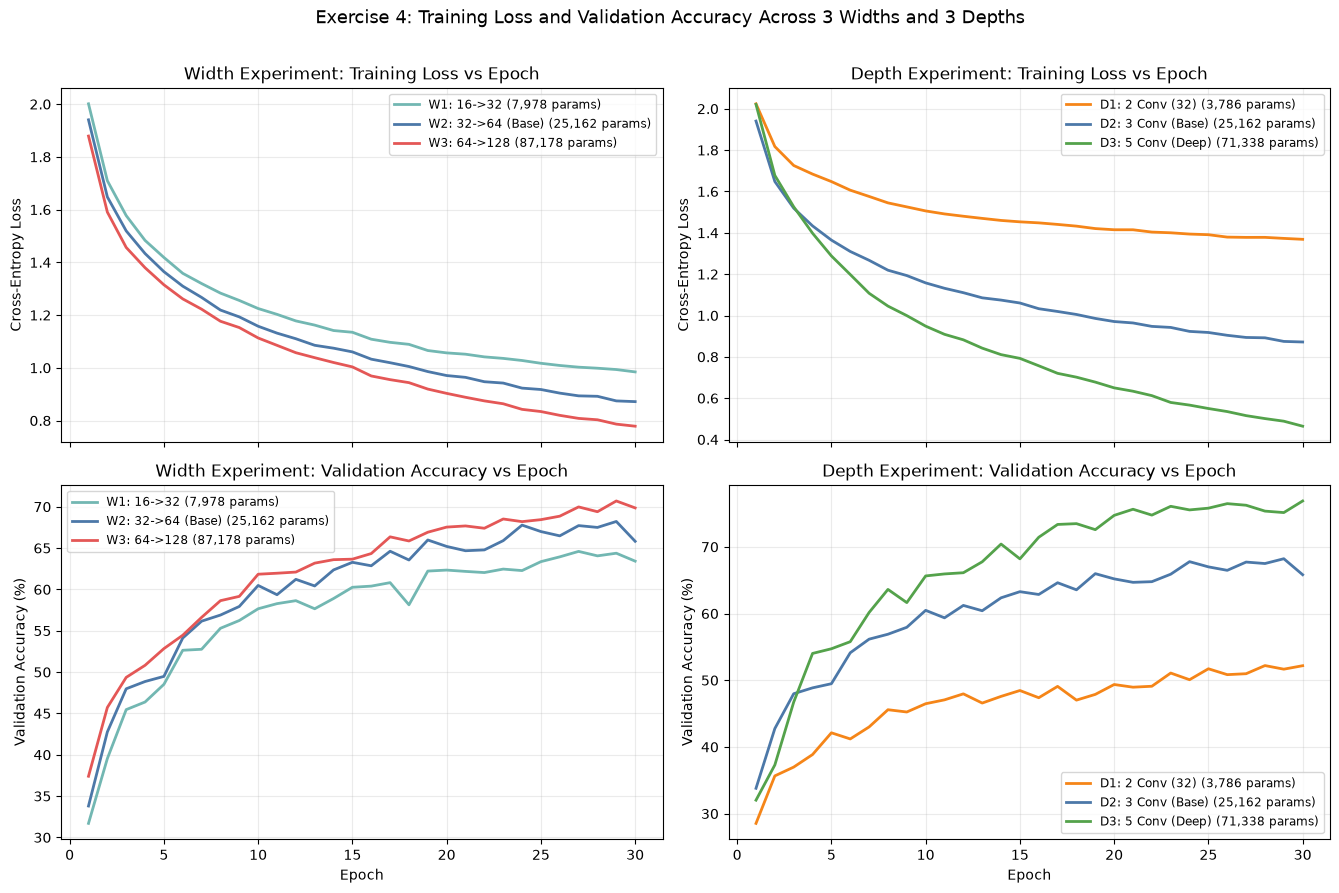

In [7]:
width_ids = ["W1", "W2", "W3"]
depth_ids = ["D1", "D2", "D3"]

width_colors = {"W1": "#72b7b2", "W2": "#4c78a8", "W3": "#e45756"}
depth_colors = {"D1": "#f58518", "D2": "#4c78a8", "D3": "#54a24b"}

figure, axes = plt.subplots(2, 2, figsize=(13.5, 8.8), sharex=True)

for vid in width_ids:
    df = variation_results[vid]["history"]
    label = f"{ variation_results[vid]['summary']['short_label'] } ({variation_results[vid]['summary']['parameter_count']:,} params)"
    axes[0, 0].plot(df["epoch"], df["train_loss"], label=label, color=width_colors[vid], linewidth=2.0)
    axes[1, 0].plot(df["epoch"], df["val_accuracy"], label=label, color=width_colors[vid], linewidth=2.0)

for vid in depth_ids:
    df = variation_results[vid]["history"]
    label = f"{ variation_results[vid]['summary']['short_label'] } ({variation_results[vid]['summary']['parameter_count']:,} params)"
    axes[0, 1].plot(df["epoch"], df["train_loss"], label=label, color=depth_colors[vid], linewidth=2.0)
    axes[1, 1].plot(df["epoch"], df["val_accuracy"], label=label, color=depth_colors[vid], linewidth=2.0)

axes[0, 0].set(title="Width Experiment: Training Loss vs Epoch", ylabel="Cross-Entropy Loss")
axes[0, 1].set(title="Depth Experiment: Training Loss vs Epoch", ylabel="Cross-Entropy Loss")
axes[1, 0].set(title="Width Experiment: Validation Accuracy vs Epoch", xlabel="Epoch", ylabel="Validation Accuracy (%)")
axes[1, 1].set(title="Depth Experiment: Validation Accuracy vs Epoch", xlabel="Epoch", ylabel="Validation Accuracy (%)")

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8.8)

figure.suptitle("Exercise 4: Training Loss and Validation Accuracy Across 3 Widths and 3 Depths", fontsize=13, y=1.01)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise4 training curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Training Trajectory Analysis.**
- In the **width experiment (left column)**, the wide network (`W3: 64->128`) has lower training loss and higher validation accuracy than `W2` and `W1` at every one of the 30 epochs. All three width curves are still improving at epoch 30 (best epochs 27–29), so none has fully converged within the budget.
- In the **depth experiment (right column)**, the shallow 2-layer CNN (`D1`) learns slowly and reaches only 52.2% validation accuracy, still creeping upwards at epoch 30. It is limited by capacity rather than saturated: with only 3,786 parameters, 32 feature maps, and a receptive field of $8 \times 8$ pixels before global average pooling, it can only combine small local patterns, not object-level shapes. `D3` improves fastest; its validation loss stops improving after about epoch 23 (best 0.680) while its training loss keeps falling (0.579 → 0.465 by epoch 30), the onset of overfitting.

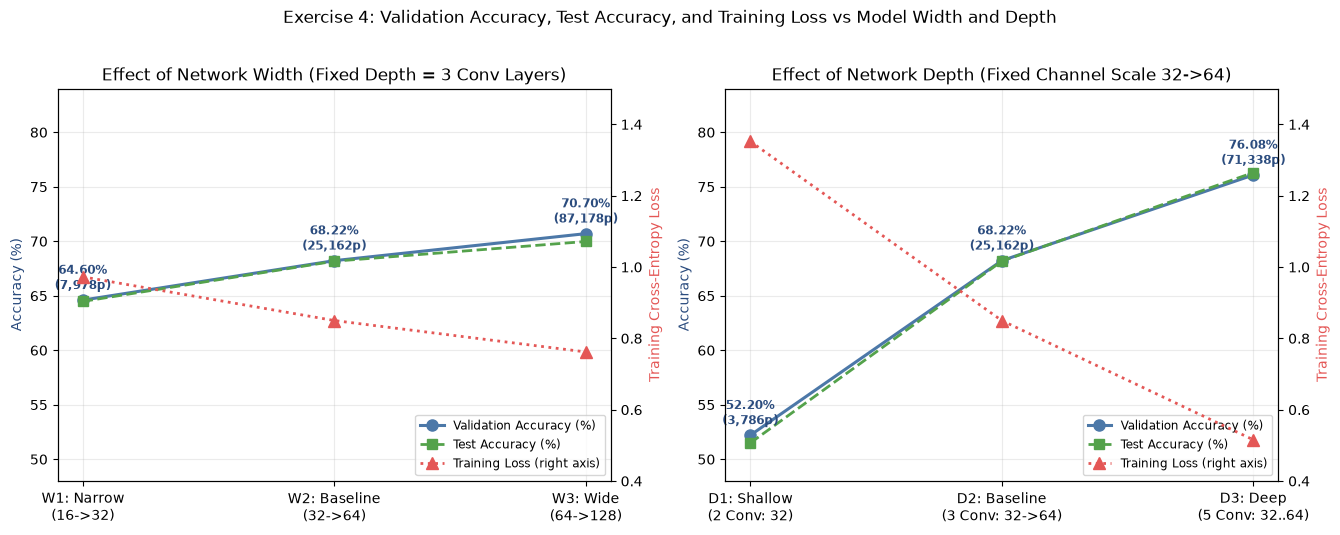

In [8]:
width_df = comparison_df[comparison_df["Group"] == "Width"].reset_index(drop=True)
depth_df = comparison_df[comparison_df["Group"] == "Depth"].reset_index(drop=True)

figure, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Panel 1: Width variations
x_w = np.arange(len(width_df))
ax_w_acc = axes[0]
ax_w_loss = ax_w_acc.twinx()

l1 = ax_w_acc.plot(x_w, width_df["Val Accuracy (%)"], marker="o", linewidth=2.2, markersize=8, color="#4c78a8", label="Validation Accuracy (%)")
l2 = ax_w_acc.plot(x_w, width_df["Test Accuracy (%)"], marker="s", linewidth=2.0, markersize=7, linestyle="--", color="#54a24b", label="Test Accuracy (%)")
l3 = ax_w_loss.plot(x_w, width_df["Train Loss"], marker="^", linewidth=2.0, markersize=8, linestyle=":", color="#e45756", label="Training Loss (right axis)")

for i, row in width_df.iterrows():
    ax_w_acc.annotate(
        f"{row['Val Accuracy (%)']:.2f}%\n({row['Trainable Parameters']:,}p)",
        xy=(i, row["Val Accuracy (%)"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        color="#2b4c7e",
        fontweight="bold",
    )

ax_w_acc.set_xticks(x_w)
ax_w_acc.set_xticklabels(["W1: Narrow\n(16->32)", "W2: Baseline\n(32->64)", "W3: Wide\n(64->128)"])
ax_w_acc.set_ylabel("Accuracy (%)", color="#2b4c7e")
ax_w_loss.set_ylabel("Training Cross-Entropy Loss", color="#e45756")
ax_w_acc.set_ylim(48, 84)
ax_w_loss.set_ylim(0.4, 1.5)
ax_w_acc.set_title("Effect of Network Width (Fixed Depth = 3 Conv Layers)")
ax_w_acc.grid(alpha=0.25)

lines_w = l1 + l2 + l3
labels_w = [l.get_label() for l in lines_w]
ax_w_acc.legend(lines_w, labels_w, loc="lower right", fontsize=8.5)

# Panel 2: Depth variations
x_d = np.arange(len(depth_df))
ax_d_acc = axes[1]
ax_d_loss = ax_d_acc.twinx()

d1 = ax_d_acc.plot(x_d, depth_df["Val Accuracy (%)"], marker="o", linewidth=2.2, markersize=8, color="#4c78a8", label="Validation Accuracy (%)")
d2 = ax_d_acc.plot(x_d, depth_df["Test Accuracy (%)"], marker="s", linewidth=2.0, markersize=7, linestyle="--", color="#54a24b", label="Test Accuracy (%)")
d3 = ax_d_loss.plot(x_d, depth_df["Train Loss"], marker="^", linewidth=2.0, markersize=8, linestyle=":", color="#e45756", label="Training Loss (right axis)")

for i, row in depth_df.iterrows():
    ax_d_acc.annotate(
        f"{row['Val Accuracy (%)']:.2f}%\n({row['Trainable Parameters']:,}p)",
        xy=(i, row["Val Accuracy (%)"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        color="#2b4c7e",
        fontweight="bold",
    )

ax_d_acc.set_xticks(x_d)
ax_d_acc.set_xticklabels(["D1: Shallow\n(2 Conv: 32)", "D2: Baseline\n(3 Conv: 32->64)", "D3: Deep\n(5 Conv: 32..64)"])
ax_d_acc.set_ylabel("Accuracy (%)", color="#2b4c7e")
ax_d_loss.set_ylabel("Training Cross-Entropy Loss", color="#e45756")
ax_d_acc.set_ylim(48, 84)
ax_d_loss.set_ylim(0.4, 1.5)
ax_d_acc.set_title("Effect of Network Depth (Fixed Channel Scale 32->64)")
ax_d_acc.grid(alpha=0.25)

lines_d = d1 + d2 + d3
labels_d = [l.get_label() for l in lines_d]
ax_d_acc.legend(lines_d, labels_d, loc="lower right", fontsize=8.5)

figure.suptitle("Exercise 4: Validation Accuracy, Test Accuracy, and Training Loss vs Model Width and Depth", fontsize=12.5, y=1.02)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise4 width depth comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Width and Depth Trend Analysis.** Training loss falls and validation/test accuracy rises as either width or depth increases. Width shows clearly diminishing returns: `W1 -> W2` gains 3.6 points of validation accuracy for 17,184 extra parameters, while `W2 -> W3` gains 2.5 points for 62,016 extra parameters. Depth gives larger gains at every step (+16.0 points from `D1` to `D2`, +7.9 from `D2` to `D3`), although part of the `D1 -> D2` jump comes from adding the 64-channel layer and a second pooling stage, not only from the extra layer (see the design note in Section 3).

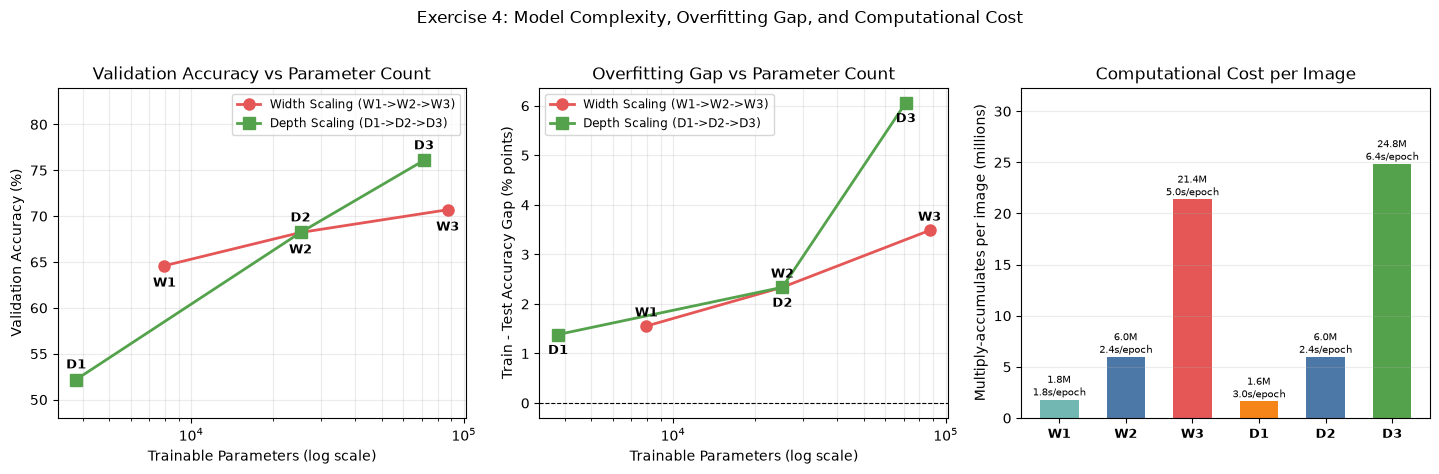

In [9]:
figure, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# Plot 1: Val Accuracy vs Parameter Count (log scale)
axes[0].plot(width_df["Trainable Parameters"], width_df["Val Accuracy (%)"], "-o", color="#e45756", linewidth=2, markersize=8, label="Width Scaling (W1->W2->W3)")
axes[0].plot(depth_df["Trainable Parameters"], depth_df["Val Accuracy (%)"], "-s", color="#54a24b", linewidth=2, markersize=8, label="Depth Scaling (D1->D2->D3)")
for _, r in comparison_df.iterrows():
    offset = (0, 8) if r["Group"] == "Depth" else (0, -15)
    axes[0].annotate(r["ID"], (r["Trainable Parameters"], r["Val Accuracy (%)"]), xytext=offset, textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
axes[0].set_xscale("log")
axes[0].set_xlabel("Trainable Parameters (log scale)")
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].set_title("Validation Accuracy vs Parameter Count")
axes[0].set_ylim(48, 84)
axes[0].grid(True, which="both", alpha=0.25)
axes[0].legend(fontsize=8.5)

# Plot 2: Generalisation Gap (Train - Test Accuracy) vs Parameter Count
axes[1].plot(width_df["Trainable Parameters"], width_df["Train - Test Gap (%)"], "-o", color="#e45756", linewidth=2, markersize=8, label="Width Scaling (W1->W2->W3)")
axes[1].plot(depth_df["Trainable Parameters"], depth_df["Train - Test Gap (%)"], "-s", color="#54a24b", linewidth=2, markersize=8, label="Depth Scaling (D1->D2->D3)")
for _, r in comparison_df.iterrows():
    offset = (0, 7) if r["Group"] == "Width" else (0, -14)
    axes[1].annotate(r["ID"], (r["Trainable Parameters"], r["Train - Test Gap (%)"]), xytext=offset, textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
axes[1].axhline(0.0, color="black", linestyle="--", linewidth=0.8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Trainable Parameters (log scale)")
axes[1].set_ylabel("Train - Test Accuracy Gap (% points)")
axes[1].set_title("Overfitting Gap vs Parameter Count")
axes[1].grid(True, which="both", alpha=0.25)
axes[1].legend(fontsize=8.5)

# Plot 3: Computational cost. MACs per image is the reliable measure; the measured median
# epoch time is printed above each bar for reference (it also includes fixed overheads such
# as data transfer and kernel launches, and varies with GPU load).
bar_colors = ["#72b7b2", "#4c78a8", "#e45756", "#f58518", "#4c78a8", "#54a24b"]
x_all = np.arange(len(comparison_df))
bars = axes[2].bar(x_all, comparison_df["MACs per Image (M)"], color=bar_colors, width=0.58)
axes[2].set_xticks(x_all)
axes[2].set_xticklabels(comparison_df["ID"], fontsize=9.5, fontweight="bold")
axes[2].set_ylabel("Multiply-accumulates per image (millions)")
axes[2].set_title("Computational Cost per Image")
axes[2].set_ylim(0, max(comparison_df["MACs per Image (M)"]) * 1.3)
axes[2].grid(axis="y", alpha=0.25)
for bar, epoch_time in zip(bars, comparison_df["Median Epoch Time (s)"]):
    h = bar.get_height()
    axes[2].annotate(f"{h:.1f}M\n{epoch_time:.1f}s/epoch", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5)

figure.suptitle("Exercise 4: Model Complexity, Overfitting Gap, and Computational Cost", fontsize=12.5, y=1.02)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "exercise4 complexity tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

**Complexity and Efficiency Trade-off Analysis.**
- **Accuracy vs parameters (left).** The depth curve lies above the width curve at large parameter counts: `D3` outperforms `W3` with 18% fewer parameters.
- **Overfitting vs parameters (middle).** The smallest models have the smallest gaps (`D1` +1.4, `W1` +1.6 points), which with their high training loss indicates underfitting (high bias). The gap grows with capacity, to +3.5 points for `W3` and +6.1 points for `D3`, indicating the onset of overfitting (higher variance).
- **Computational cost (right).** MACs per image grow with both width ($1.8\text{M} \rightarrow 6.0\text{M} \rightarrow 21.4\text{M}$) and depth ($1.6\text{M} \rightarrow 6.0\text{M} \rightarrow 24.8\text{M}$); `D3` is the most expensive model. The measured median epoch times follow the same trend for the large models (`W3` 5.0 s, `D3` 6.4 s) but are unreliable for small ones: `D1` took longer per epoch (3.0 s) than `D2` (2.4 s) despite needing 3.7× fewer MACs. For networks this small, epoch time is dominated by fixed per-batch overheads (Python loop, host-to-GPU transfers, kernel launches) and by other load on the machine, which is why MACs are used as the main complexity measure.

## 8. Per-Class Test Accuracy Breakdown Across All Width and Depth Variations

We also compute the per-class test accuracy for all 10 CIFAR-10 categories across the architectures and save it to `outputs/exercise4 per_class_accuracy.csv`.

In [10]:
per_class_cols = {}
for spec in VARIATION_SPECS:
    vid = spec["variation_id"]
    test_preds, test_labels = variation_results[vid]["test_outputs"]
    cm = confusion_matrix(test_labels, test_preds)
    class_acc = 100.0 * cm.diagonal() / cm.sum(axis=1)
    per_class_cols[f"{vid} ({spec['short_label']})"] = pd.Series(class_acc, index=CLASS_NAMES)

per_class_df = pd.DataFrame(per_class_cols)
per_class_df["W3 - W1 Gain"] = per_class_df.iloc[:, 2] - per_class_df.iloc[:, 0]
per_class_df["D3 - D1 Gain"] = per_class_df.iloc[:, 5] - per_class_df.iloc[:, 3]
per_class_df.round(2).to_csv(OUTPUT_DIR / "exercise4 per_class_accuracy.csv")
display(per_class_df.round(2))

,W1 (W1: 16->32),W2 (W2: 32->64 (Base)),W3 (W3: 64->128),D1 (D1: 2 Conv (32)),D2 (D2: 3 Conv (Base)),D3 (D3: 5 Conv (Deep)),W3 - W1 Gain,D3 - D1 Gain
airplane,62.2,63.6,71.8,44.4,63.6,80.9,9.6,36.5
automobile,81.1,67.7,77.7,59.4,67.7,87.2,-3.4,27.8
bird,41.6,52.5,47.7,28.9,52.5,66.4,6.1,37.5
cat,40.4,53.2,64.1,46.7,53.2,60.7,23.7,14.0
deer,61.9,66.3,59.7,38.2,66.3,74.3,-2.2,36.1
dog,63.6,63.3,62.3,45.6,63.3,63.9,-1.3,18.3
frog,69.1,72.3,75.4,66.1,72.3,79.4,6.3,13.3
horse,73.2,76.6,77.9,60.3,76.6,83.9,4.7,23.6
ship,77.3,82.1,83.6,66.6,82.1,83.2,6.3,16.6
truck,74.4,84.1,79.6,58.7,84.1,83.1,5.2,24.4


## 9. Critical Discussion and Conclusion (Requirement 7)

### Summary of results
| Variation | Conv layers | Parameters | MACs / image | Train loss | Val acc. (%) | Test acc. (%) | Gap (pp) |
|---|---|---|---|---|---|---|---|
| W1 narrow (16-32) | 3 | 7,978 | 1.81M | 0.973 | 64.60 | 64.48 | +1.55 |
| W2 / D2 baseline (32-64) | 3 | 25,162 | 5.97M | 0.850 | 68.22 | 68.17 | +2.34 |
| W3 wide (64-128) | 3 | 87,178 | 21.38M | 0.762 | 70.70 | 69.98 | +3.48 |
| D1 shallow (32) | 2 | 3,786 | 1.62M | 1.352 | 52.20 | 51.49 | +1.38 |
| D3 deep (32-32-64-64) | 5 | 71,338 | 24.85M | 0.516 | 76.08 | 76.30 | +6.06 |

### Model complexity and accuracy
- **Width.** More kernels per layer let each stage detect more distinct patterns (colours, edge orientations, textures), so accuracy rises steadily with width. But parameters and compute grow roughly quadratically with width while accuracy gains shrink, so widening alone is an expensive way to improve this network.
- **Depth.** Extra layers add non-linear compositions and enlarge the receptive field (from $8 \times 8$ pixels in `D1` to $18 \times 18$ in `D2` and $24 \times 24$ in `D3`, most of the image), so later layers can combine edges into parts and parts into objects. This gave the largest accuracy gains per parameter. The depth comparison is not perfectly isolated, since `D1` also has fewer channels and one fewer pooling stage, but `D3` vs `W3` (similar parameter count, both with two pooling stages) supports the conclusion that depth was the more effective use of parameters here.

### Training behaviour and overfitting
- The two smallest models (`D1`, `W1`) have high training loss and small gaps: they **underfit** (high bias), and more training alone would not close the gap to the larger models.
- As capacity grows, training loss falls faster than validation loss and the train–test gap widens, reaching +6.1 points for `D3`, whose validation loss stopped improving after epoch 23 while training loss kept falling. This is the onset of **overfitting** (higher variance). None of the models overfits severely within 30 epochs, unlike the 1.7M-parameter MLP of Exercise 1 (gap +12.4 points, best epoch 6).
- This is the bias–variance trade-off in practice: more capacity lowers bias and raises accuracy until variance starts to dominate.

### Computational complexity
Compute cost grows with both width and depth, and `D3` is the most expensive model (24.85M MACs per image, about 4× the baseline). Its higher accuracy is therefore bought with more computation, not obtained for free; it is more efficient than `W3` per parameter and per extra MAC, but not cheaper. Measured epoch time is a noisy measure for networks this small and should be read alongside the MAC counts.

### Links to Exercise 3 and limitations
- In Exercise 3, dropout and augmentation reduced accuracy on the small baseline because it had little overfitting to correct. The larger models here, especially `D3`, show a clearly larger gap, so they are where regularisation would be *expected* to help more. This was not tested here and would be a natural next experiment.
- All results come from a single seed and a fixed 30-epoch budget; most models were still improving at the end, so longer training (or a learning-rate schedule) could change the margins between variations. Differences of under about one point should not be over-interpreted.